# Sections 2 and 6 for `03_Modelling.ipynb`: shared backtest + Random Forest
Daniel's part. The cells below are written to be pasted into `03_Modelling.ipynb`:
- **Section 2 (shared):** backtest quarters, training rows, feature preparation and metrics. Every model should use these same functions, so the comparison and the ensemble use exactly the same days.
- **Section 6:** Random Forest, tuned on the validation quarters, then scored once on 2025.

Run from `notebooks/`, after section 1 (Setup) of `03_Modelling.ipynb`.

In [1]:
# ---- Section 1 (Setup), minimal version so this notebook runs on its own ----
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import poisson
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
model_table = pd.read_csv(ROOT / "data/processed/model_table.csv", parse_dates=["date"])
LEAD_MONTHS = 1
SEED = 42
BLUE, ORANGE, GREY = "#2F6DB5", "#D9622B", "#8A8F98"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E3E5E8", "font.size": 12})

Matplotlib is building the font cache; this may take a moment.


--------
## 2. How we evaluate (shared code)

**Rolling origin by quarter.** For each quarter we forecast:
- the **cutoff** is 1 month before the quarter starts (`LEAD_MONTHS`);
- the model trains only on rows **from 2019Q3 up to the cutoff**, without the COVID days;
- it then predicts **every day** of that quarter. We score weekends + holidays (main) and all days (secondary).

| Part | Quarters | Used for |
|---|---|---|
| Validation | 2023Q1 – 2024Q4 | tuning, model choice, ensemble weights |
| Test | 2025Q1 – 2025Q4 | final score, **used once** |

**Metrics:** MAE (accidents per day, easy to explain), RMSE (penalises missed peaks), Poisson deviance (the right loss for counts) and bias (mean error: negative = under-forecasting = too few resources). No MAPE: many region-days have 0 accidents.

In [2]:
TRAIN_START = pd.Timestamp("2019-07-01")   # first quarter with complete history features

def quarter_periods(first, last):
    """One row per forecast quarter: its cutoff (1 month before it starts), start and end."""
    rows = []
    for q in pd.period_range(first, last, freq="Q"):
        start = q.start_time.normalize()
        rows.append({"quarter": str(q), "cutoff": start - pd.DateOffset(months=LEAD_MONTHS),
                     "start": start, "end": q.end_time.normalize()})
    return pd.DataFrame(rows)

VALID = quarter_periods("2023Q1", "2024Q4")
TEST = quarter_periods("2025Q1", "2025Q4")

data = model_table.copy()
y = data["accidents"].to_numpy()
day_off = ((data["is_weekend"] == 1) | (data["is_holiday"] == 1)).to_numpy()   # weekend or holiday

def train_rows(cutoff):
    return ((data["date"] >= TRAIN_START) & (data["date"] < cutoff) & (data["is_covid"] == 0)).to_numpy()

def quarter_rows(periods):
    mask = np.zeros(len(data), bool)
    for p in periods.itertuples():
        mask |= ((data["date"] >= p.start) & (data["date"] <= p.end)).to_numpy()
    return mask

VALID

,quarter,cutoff,start,end
0,2023Q1,2022-12-01,2023-01-01,2023-03-31
1,2023Q2,2023-03-01,2023-04-01,2023-06-30
2,2023Q3,2023-06-01,2023-07-01,2023-09-30
3,2023Q4,2023-09-01,2023-10-01,2023-12-31
4,2024Q1,2023-12-01,2024-01-01,2024-03-31
5,2024Q2,2024-03-01,2024-04-01,2024-06-30
6,2024Q3,2024-06-01,2024-07-01,2024-09-30
7,2024Q4,2024-09-01,2024-10-01,2024-12-31


### Empty values: most of them are not missing data
- `days_to_holiday` / `days_after_holiday` are empty when **no holiday is within 3 days**. That is information, not a missing value, so we code it as **4** ("more than 3 days away"). Filling it with the mean (≈1.4) would wrongly put every normal day 1 day from a holiday. **For the GLM:** use the same code, or turn these columns into categories (0, 1, 2, 3, "none").
- **2020Q3 history:** the 91 days before its cutoff are all COVID days, so `hist_avg_91d`, `hist_same_q_last_year` and `hist_trend` are empty for that quarter only (460 rows). We fall back on the 365-day average and a neutral trend of 1.
- After this, the training rows have no empty values left, so the **same rows work for all three models**.

In [3]:
DOW = {"Monday": 0, "Tuesday": 1, "Wednesday": 2, "Thursday": 3, "Friday": 4, "Saturday": 5, "Sunday": 6}
FEATURES = ["is_weekend", "dow", "month", "is_holiday", "days_to_holiday", "days_after_holiday",
            "is_holiday_window", "is_bridge_day", "is_long_weekend", "is_school_vacation",
            "rain_day_prob", "heavy_rain_prob", "avg_daily_precip", "avg_temp_max", "avg_humidity_min",
            "fire_weather_prob",
            "hist_avg_91d", "hist_avg_365d", "hist_dayoff_avg_365d", "hist_same_q_last_year", "hist_trend"]

def prepare_features(df):
    X = df.copy()
    X["dow"] = X["day_of_week"].map(DOW)
    X["days_to_holiday"] = X["days_to_holiday"].fillna(4)       # 4 = no holiday within 3 days
    X["days_after_holiday"] = X["days_after_holiday"].fillna(4)
    X["hist_avg_91d"] = X["hist_avg_91d"].fillna(X["hist_avg_365d"])                    # 2020Q3 only
    X["hist_same_q_last_year"] = X["hist_same_q_last_year"].fillna(X["hist_avg_365d"])  # 2020Q3 only
    X["hist_trend"] = X["hist_trend"].fillna(1.0)                                       # 2020Q3 only
    for r in sorted(df["region"].unique()):
        X[f"reg_{r}"] = (df["region"] == r).astype(int)
    return X[FEATURES + [c for c in X.columns if c.startswith("reg_")]]

X_all = prepare_features(data)
print("Empty values left in training rows:", int(X_all[train_rows(TEST.cutoff.max())].isna().sum().sum()))

def score(pred, periods, name):
    """Metrics on weekend+holiday days (main) and on all days of the given quarters."""
    q = quarter_rows(periods); out = []
    for days, mask in [("weekend+holiday", q & day_off), ("all days", q)]:
        yt, yp = y[mask], np.clip(np.asarray(pred)[mask], 1e-6, None)
        out.append({"model": name, "days": days, "MAE": mean_absolute_error(yt, yp),
                    "RMSE": mean_squared_error(yt, yp) ** 0.5, "Poisson dev": mean_poisson_deviance(yt, yp),
                    "bias": (yp - yt).mean(), "n": int(mask.sum())})
    return out

Empty values left in training rows: 0


### Reference baseline (Section 3 owner may replace it)
Same day type, last year: for a weekend/holiday, the average accidents per day off in the 365 days before the cutoff (`hist_dayoff_avg_365d`); for a weekday, the overall 365-day average. It uses only history, so it is known at the cutoff.

In [4]:
baseline = np.where(day_off, data["hist_dayoff_avg_365d"], data["hist_avg_365d"])
pd.DataFrame(score(baseline, VALID, "Baseline")).round(3)

,model,days,MAE,RMSE,Poisson dev,bias,n
0,Baseline,weekend+holiday,1.217,1.546,1.148,-0.064,1170
1,Baseline,all days,1.172,1.522,1.152,-0.061,3655


### The noise floor: how good can any model be?
Counts of ~2 accidents per region per day follow a Poisson-like distribution: even a model that knew the **true** daily mean would still miss by about 1.2 accidents a day. We compute that floor so the results can be read honestly (Raul: *"How far is it from the error floor?"*). Overdispersion check: within each region the variance/mean ratio is 1.03–1.11, so Poisson is a fair assumption.

In [5]:
def poisson_floor(lam):
    """Expected MAE and Poisson deviance if a model knew the true mean `lam` of each day."""
    k = np.arange(0, 40)[:, None]; pk = poisson.pmf(k, lam[None, :])
    mae = (pk * np.abs(k - lam[None, :])).sum(0)
    unit_dev = 2 * (np.where(k > 0, k * np.log(np.where(k > 0, k, 1) / lam[None, :]), 0) - (k - lam[None, :]))
    return mae.mean(), (pk * unit_dev).sum(0).mean()

print(data.groupby("region")["accidents"].agg(lambda s: s.var() / s.mean()).round(2).rename("variance / mean"))

region
Centro-Oeste    1.03
Nordeste        1.11
Norte           1.07
Sudeste         1.10
Sul             1.07
Name: variance / mean, dtype: float64


--------
## 6. Model 3 - Random Forest

`RandomForestRegressor(criterion="poisson")`, trained on **all days** (weekdays teach the regional level), scored mainly on weekends + holidays.

**Two ways to set the target:**
- **count:** predict the number of accidents directly;
- **ratio to level:** predict accidents ÷ the region's 365-day average, then multiply back. Trees cannot extrapolate beyond the values seen in training, so learning a *relative* effect (e.g. "+15% on a long weekend") lets the forecast follow the level when it moves.

In [6]:
def backtest(make_model, periods, target="count"):
    """Rolling origin: for each quarter, fit on the rows before its cutoff and predict all its days."""
    pred = np.full(len(data), np.nan)
    level = data["hist_avg_365d"].fillna(data["hist_avg_91d"]).to_numpy()
    for p in periods.itertuples():
        tr, q = train_rows(p.cutoff), quarter_rows(pd.DataFrame([p._asdict()]))
        model = make_model()
        if target == "ratio":
            model.fit(X_all[tr], y[tr] / level[tr]); pred[q] = model.predict(X_all[q]) * level[q]
        else:
            model.fit(X_all[tr], y[tr]); pred[q] = model.predict(X_all[q])
    return pred

### 6.1 Tuning on the validation quarters (2023–2024)

In [7]:
results = []
for leaf in [5, 20, 50]:
    for max_feat in [0.33, 0.6]:
        rf = lambda: RandomForestRegressor(n_estimators=200, criterion="poisson", min_samples_leaf=leaf,
                                           max_features=max_feat, n_jobs=-1, random_state=SEED)
        results += score(backtest(rf, VALID), VALID, f"RF leaf={leaf} max_features={max_feat}")
tuning = pd.DataFrame(results)
tuning[tuning["days"] == "weekend+holiday"].sort_values("Poisson dev").round(4)

,model,days,MAE,RMSE,Poisson dev,bias,n
8,RF leaf=50 max_features=0.33,weekend+holiday,1.2074,1.5348,1.1339,-0.0130,1170
10,RF leaf=50 max_features=0.6,weekend+holiday,1.2079,1.5354,1.1342,0.0077,1170
4,RF leaf=20 max_features=0.33,weekend+holiday,1.2082,1.5389,1.1401,0.0029,1170
6,RF leaf=20 max_features=0.6,weekend+holiday,1.2071,1.5393,1.1411,0.0183,1170
0,RF leaf=5 max_features=0.33,weekend+holiday,1.2065,1.5452,1.1543,0.0077,1170
2,RF leaf=5 max_features=0.6,weekend+holiday,1.2103,1.5489,1.1597,0.0142,1170


All settings land within ~0.03 of each other: the result is not driven by the hyper-parameters. We keep **`min_samples_leaf=50`, `max_features=0.33`** (lowest Poisson deviance and RMSE: large leaves average out the noise), with 500 trees, and compare the two targets.

In [8]:
make_rf = lambda: RandomForestRegressor(n_estimators=500, criterion="poisson", min_samples_leaf=50,
                                        max_features=0.33, n_jobs=-1, random_state=SEED)
rf_valid_count = backtest(make_rf, VALID, target="count")
rf_valid_ratio = backtest(make_rf, VALID, target="ratio")
valid_table = pd.DataFrame(score(baseline, VALID, "Baseline") + score(rf_valid_count, VALID, "RF count")
                           + score(rf_valid_ratio, VALID, "RF ratio to level"))
floor_v = poisson_floor(np.clip(rf_valid_ratio[quarter_rows(VALID) & day_off], 1e-3, None))
print("Noise floor, validation weekend+holiday: MAE %.3f | Poisson dev %.3f" % floor_v)
valid_table.round(4)

Noise floor, validation weekend+holiday: MAE 1.180 | Poisson dev 1.104


,model,days,MAE,RMSE,Poisson dev,bias,n
0,Baseline,weekend+holiday,1.2171,1.5463,1.1477,-0.0637,1170
1,Baseline,all days,1.1722,1.5216,1.1522,-0.0606,3655
2,RF count,weekend+holiday,1.2079,1.5351,1.1344,-0.0143,1170
3,RF count,all days,1.1618,1.5199,1.1523,-0.1096,3655
4,RF ratio to level,weekend+holiday,1.1982,1.5271,1.1282,0.0002,1170
5,RF ratio to level,all days,1.1593,1.5148,1.1475,-0.1101,3655


**Choice (made on validation, before the test):** **RF ratio to level**. It has the lowest Poisson deviance and MAE on weekends + holidays, and zero bias. The gain over the baseline is small (MAE 1.198 vs 1.217), because both are already close to the noise floor (≈1.18).

### 6.2 Final test on 2025 (used once)

In [9]:
rf_test = backtest(make_rf, TEST, target="ratio")
test_table = pd.DataFrame(score(baseline, TEST, "Baseline") + score(rf_test, TEST, "RF ratio to level"))
floor_t = poisson_floor(np.clip(rf_test[quarter_rows(TEST) & day_off], 1e-3, None))
print("Noise floor, test weekend+holiday: MAE %.3f | Poisson dev %.3f" % floor_t)
test_table.round(4)

Noise floor, test weekend+holiday: MAE 1.228 | Poisson dev 1.099


,model,days,MAE,RMSE,Poisson dev,bias,n
0,Baseline,weekend+holiday,1.2262,1.6104,1.1613,-0.0374,585
1,Baseline,all days,1.2022,1.5628,1.1270,0.0043,1825
2,RF ratio to level,weekend+holiday,1.2475,1.6211,1.1604,0.1060,585
3,RF ratio to level,all days,1.1909,1.5569,1.1192,-0.0126,1825


In [10]:
# The planning decision is quarterly: how far off is the total per region and quarter?
q_test = quarter_rows(TEST)
totals = (data.assign(RF=rf_test, Baseline=baseline)[q_test]
              .groupby(["year_quarter", "region"])[["accidents", "RF", "Baseline"]].sum())
for m in ["RF", "Baseline"]:
    totals[f"{m} error %"] = (totals[m] / totals["accidents"] - 1) * 100
print("Mean absolute error of the quarter total per region:  RF %.1f%%  |  Baseline %.1f%%"
      % (totals["RF error %"].abs().mean(), totals["Baseline error %"].abs().mean()))
totals.round(1)

Mean absolute error of the quarter total per region:  RF 7.8%  |  Baseline 8.8%


accidents     RF  Baseline  RF error %  \
year_quarter region                                                 
2025Q1       Centro-Oeste        115  114.9     118.9        -0.1   
             Nordeste            194  224.8     247.4        15.9   
             Norte                50   56.9      63.6        13.8   
             Sudeste             322  313.7     326.1        -2.6   
             Sul                 279  301.6     302.8         8.1   
2025Q2       Centro-Oeste        121  117.3     121.6        -3.1   
             Nordeste            244  219.9     241.5        -9.9   
             Norte                57   56.1      60.9        -1.5   
             Sudeste             330  324.0     333.6        -1.8   
             Sul                 318  302.8     301.0        -4.8   
2025Q3       Centro-Oeste        104  128.0     125.7        23.1   
             Nordeste            254  232.1     237.7        -8.6   
             Norte                70   56.0      54.5       -20.0   
             Sudeste             366  349.0     346.6        -4.7   
             Sul                 303  322.5     317.9         6.4   
2025Q4       Centro-Oeste        122  119.5     117.7        -2.1   
             Nordeste            243  251.2     238.7         3.4   
             Norte                69   60.4      57.5       -12.5   
             Sudeste             388  356.9     342.9        -8.0   
             Sul                 314  332.4     314.1         5.9   

                           Baseline error %  
year_quarter region                          
2025Q1       Centro-Oeste               3.4  
             Nordeste                  27.5  
             Norte                     27.2  
             Sudeste                    1.3  
             Sul                        8.5  
2025Q2       Centro-Oeste               0.5  
             Nordeste                  -1.0  
             Norte                      6.9  
             Sudeste                    1.1  
             Sul                       -5.3  
2025Q3       Centro-Oeste              20.8  
             Nordeste                  -6.4  
             Norte                    -22.1  
             Sudeste                   -5.3  
             Sul                        4.9  
2025Q4       Centro-Oeste              -3.6  
             Nordeste                  -1.8  
             Norte                    -16.6  
             Sudeste                  -11.6  
             Sul                        0.0

In [11]:
# Errors by region, weekend+holiday days of 2025
wh = q_test & day_off
by_region = (data.assign(RF=rf_test, Baseline=baseline)[wh].groupby("region")
             .apply(lambda g: pd.Series({"actual per day": g["accidents"].mean(),
                                         "MAE RF": (g["RF"] - g["accidents"]).abs().mean(),
                                         "MAE Baseline": (g["Baseline"] - g["accidents"]).abs().mean(),
                                         "bias RF": (g["RF"] - g["accidents"]).mean()})))
by_region.round(3)

,actual per day,MAE RF,MAE Baseline,bias RF
region,,,,
Centro-Oeste,1.308,0.921,0.909,0.153
Nordeste,2.564,1.475,1.428,0.271
Norte,0.744,0.660,0.688,-0.009
Sudeste,4.051,1.574,1.537,-0.102
Sul,3.462,1.607,1.569,0.217


### 6.3 What drives the forecast?

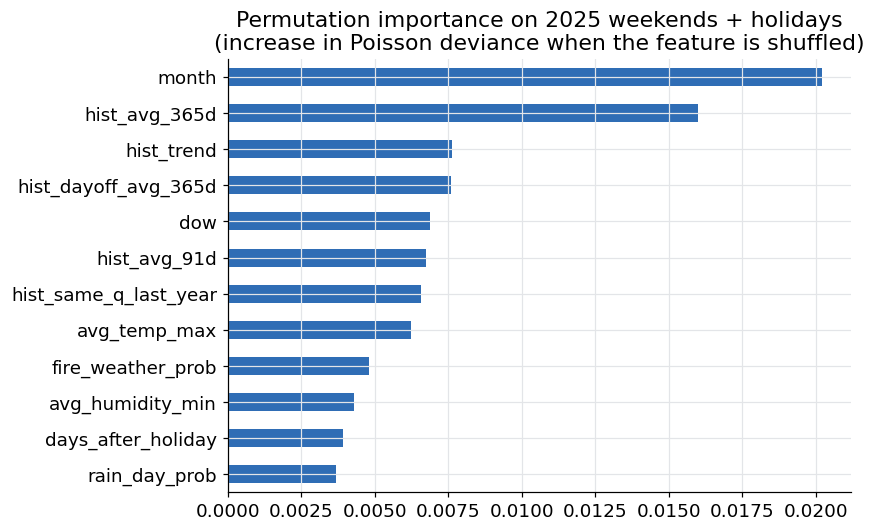

In [12]:
final_rf = make_rf()
tr = train_rows(TEST.cutoff.max())
level = data["hist_avg_365d"].fillna(data["hist_avg_91d"]).to_numpy()
final_rf.fit(X_all[tr], y[tr] / level[tr])

# Permutation importance by hand: shuffle one feature, measure how much the Poisson deviance gets worse
rng = np.random.default_rng(SEED)
X_wh, y_wh, lvl_wh = X_all[wh], y[wh], level[wh]
base_dev = mean_poisson_deviance(y_wh, final_rf.predict(X_wh) * lvl_wh)
imp = {}
for col in X_all.columns:
    worse = []
    for _ in range(10):
        Xp = X_wh.copy(); Xp[col] = rng.permutation(Xp[col].to_numpy())
        worse.append(mean_poisson_deviance(y_wh, final_rf.predict(Xp) * lvl_wh) - base_dev)
    imp[col] = np.mean(worse)
importance = pd.Series(imp).sort_values()
importance.tail(12).plot.barh(color=BLUE, figsize=(8, 5))
plt.title("Permutation importance on 2025 weekends + holidays\n(increase in Poisson deviance when the feature is shuffled)")
plt.tight_layout(); plt.show()

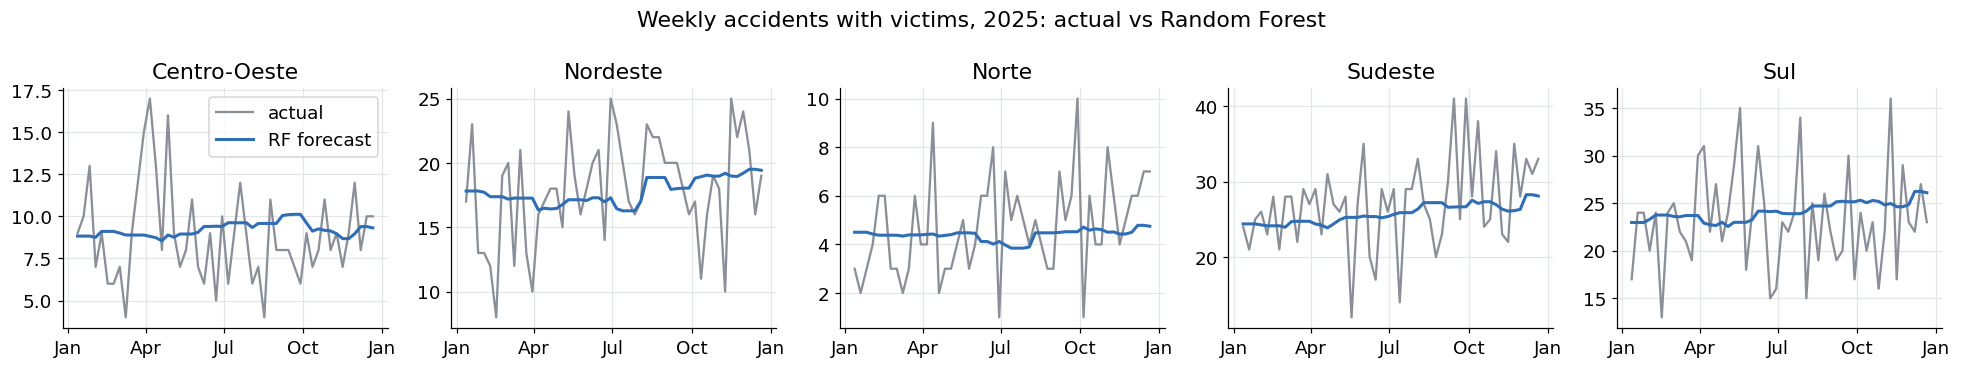

In [13]:
# Actual vs forecast, weekly totals per region in 2025
wk = (data.assign(RF=rf_test)[q_test].set_index("date").groupby("region")[["accidents", "RF"]]
          .resample("W").sum())
wk = wk[wk.index.get_level_values("date") > "2025-01-05"]       # drop the partial first week
wk = wk[wk.index.get_level_values("date") < "2025-12-28"]       # and the partial last week
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4), sharey=False)
for ax, r in zip(axes, sorted(data["region"].unique())):
    w = wk.loc[r]
    ax.plot(w.index, w["accidents"], color=GREY, label="actual")
    ax.plot(w.index, w["RF"], color=BLUE, lw=2, label="RF forecast")
    ax.set_title(r); ax.set_xlabel("")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b")); ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[0].legend(); plt.suptitle("Weekly accidents with victims, 2025: actual vs Random Forest"); plt.tight_layout(); plt.show()

### 6.4 Reading the Random Forest results
- **Hyper-parameters barely matter.** All six settings land within 0.03 MAE of each other. Large leaves (50 days) work best because they average out day-to-day noise.
- **It is close to the noise floor.** On validation the RF reaches MAE ≈1.20 against a theoretical floor of ≈1.18. On weekends and holidays, about 98% of the remaining error is irreducible Poisson noise. No algorithm can turn that into signal (principle 2: *"part of that uncertainty is irreducible"*).
- **Against the baseline:** better on validation, but **on the 2025 test it does not beat the baseline on weekends and holidays** (MAE 1.248 vs 1.226, same Poisson deviance). It is better on all days (Poisson deviance 1.119 vs 1.127) and on **quarter totals per region (7.8% vs 8.8% error)**, which is the level at which resources are planned.
- **What drives it:** **month** (seasonality) and the **regional history level** (365-day average, trend, day-off average) carry most of the information, followed by day of week and the usual temperature. The holiday features (`is_holiday`, `is_long_weekend`, bridge day) are not in the top 12. Weekends and holidays have only ~6–15% more accidents than weekdays, a small effect next to the daily noise. That is a finding for the group's story: holidays matter less than expected.
- **Drift:** in 2025 the weekend/holiday uplift was smaller than in training (+6% observed vs +14% learned), so the RF over-forecast those days (bias +0.11). That is a sign to keep retraining every quarter.

**For the business:** plan **quarterly volumes per region** from the forecast, which is accurate to within ~8%. Treat the daily numbers as an average with a wide band (Poisson interval), not as an exact count.